# NUScope workflow: from a microscope file to a citable, verifiable dataset

**NUScope** · created by Roberto dos Reis ([@rmsreis](https://github.com/rmsreis)), NUANCE Center, Northwestern University · [documentation](https://nuance-it.github.io/NUScope/)

This notebook walks through the whole NUScope workflow:

1. **Read** a microscope file: calibrated axes, one metadata schema, provenance, the instrument's DataCite DOI
2. **Look** at it in physical units
3. **Analyze**: noise, denoising, Fourier transform, particles, all in nm
4. **Save** as HDF5 with metadata, history and a cryptographic **seal**, signed with your ORCID-linked identity
5. **Verify** the file, and see what happens when someone changes it
6. **Trace** the full history (W3C PROV)
7. **Cite**: DataCite metadata for a dataset DOI linked to the instrument and the exact file
8. **Package** for a repository (RO-Crate)
9. **Studio**: the same in the browser

It runs as is: section 1 makes a small synthetic image saved the way a Hitachi S-3400 at NUANCE's EPIC facility saves its files. To use your own data, set `MY_FILE` in section 1.

```bash
pip install "nuscope[datacite,plot]"
```

## 0. Setup

Everything this notebook writes goes to a temporary folder (`WORK`).

In [1]:
import json, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import nuscope as ns
from nuscope import analyze as an

WORK = Path(tempfile.mkdtemp(prefix="nuscope-workflow-"))
print("NUScope", ns.__version__, "| working in", WORK)

NUScope 0.5.0 | working in /var/folders/r1/jgb817xs44qfx69d473y6rcm0000gn/T/nuscope-workflow-hjszqyj3


### Your identity

Files you save are signed with your researcher identity: your name, your ORCID iD and an Ed25519 key, shared by NUScope, NUScope-TOMO and NUANCE-MCP (from [EMDataBridge](https://github.com/NUANCE-IT/EMDataBridge)). Create it once, in a terminal:

```bash
emdb identity create "Your Name" --orcid 0000-0000-0000-0000
```

Without one, files are still **sealed** (tamper-evident), just not **signed**.

In [2]:
me = ns.integrity.my_key()
print(f"Signing as {me}" if me else 'No identity yet: files will be sealed, not signed (emdb identity create "Your Name" --orcid ...)')

Signing as Example Researcher (https://orcid.org/0000-0002-1825-0097) [9d02:cb2d:cfa0:a4c0]


## 1. Read a microscope file

`ns.load()` reads Thermo Fisher/FEI, Zeiss, Hitachi and JEOL SEM/FIB files natively, and Gatan DM3/DM4, Velox EMD, TIA, Bruker, EDAX, MRC and 30 more through RosettaSciIO. It also accepts `globus://<collection>/<path>`.

Set `MY_FILE` to one of your files, or leave it as `None` to use a synthetic Hitachi S-3400 image: a TIFF plus the `.txt` sidecar the instrument writes, with a 30 kV beam, 500× and 396.875 nm pixels.

In [3]:
MY_FILE = None   # e.g. "/path/to/your/FS-Ti_Sample_11-BSE.tif"

def synthetic_s3400(folder: Path) -> Path:
    """A 448 x 640 BSE-like image with bright particles, saved as an S-3400 does (TIFF + .txt sidecar)."""
    rng = np.random.default_rng(0)
    img = rng.normal(60, 8, (448, 640))
    yy, xx = np.mgrid[:448, :640]
    for _ in range(60):
        cy, cx, r = rng.integers(20, 428), rng.integers(20, 620), rng.integers(4, 12)
        img[(yy - cy) ** 2 + (xx - cx) ** 2 <= r * r] += rng.uniform(90, 150)
    import tifffile
    tif = folder / "S3400_demo.tif"
    tifffile.imwrite(tif, np.clip(img, 0, 255).astype(np.uint8))
    (folder / "S3400_demo.txt").write_text(
        "[SemImageFile]\nInstructName=S-3400\nDate=12/06/2025\nTime=17:39:19\n"
        "AcceleratingVoltage=30000 Volt\nMagnification=500\nWorkingDistance=14900 um\n"
        "PixelSize=396.875\nSignalName=BSE\n")
    return tif

path = Path(MY_FILE) if MY_FILE else synthetic_s3400(WORK)
ds = ns.load(path)
ds

<Dataset 'S3400_demo' image (448, 640) uint8 396.875 nm/px>

In [4]:
print(ds.describe())

S3400_demo · image · uint8 · 448 y @ 396.875 nm × 640 x @ 396.875 nm
  Instrument: Hitachi High-Tech S-3400
  Technique: SEM
  Voltage: 30 kV
  Magnification: 500×
  Working distance: 14.9 mm
  Detector: BSE
  Acquired: 2025-12-06T17:39:19
  history: 1 step(s); source S3400_demo.tif


### One metadata schema, whatever the vendor

The same sections for every instrument: `instrument`, `technique`, `beam`, `optics`, `detector`, `acquisition` and `sample`. Dates are ISO 8601, and the vendor's own block is kept untouched in `ds.original_metadata`.

In [5]:
for section in ("instrument", "beam", "optics", "acquisition"):
    print(f"{section:12s}", ds.metadata.get(section))

instrument   {'vendor': 'Hitachi High-Tech', 'model': 'S-3400', 'doi': '10.82427/nuance.epic.sem.s3400.2025.000001', 'doi_status': 'unverified', 'name': 'EPIC SEM Hitachi S-3400', 'facility': 'EPIC'}
beam         {'voltage_kV': 30.0}
optics       {'working_distance_mm': 14.9, 'magnification': 500.0}
acquisition  {'datetime': '2025-12-06T17:39:19'}


### The instrument's DOI

With `nuance-datacite` installed, NUScope matches the instrument against the NUANCE registry (DataCite repository [NU.NUANCE](https://doi.datacite.org/repositories/nu.nuance), prefix 10.82427) and records its DOI. The DOI goes into the metadata and the provenance, and later into the seal.

In [6]:
ins = ds.metadata["instrument"]
print("DOI:   ", ins.get("doi", "(not in the registry)"), f"[{ins.get('doi_status', '-')}]")
print("Agent: ", [a.id for a in ds.provenance.agents.values() if a.kind == "instrument"])

DOI:    10.82427/nuance.epic.sem.s3400.2025.000001 [unverified]
Agent:  ['instrument:doi:10.82427/nuance.epic.sem.s3400.2025.000001']


## 2. Look at it, in physical units

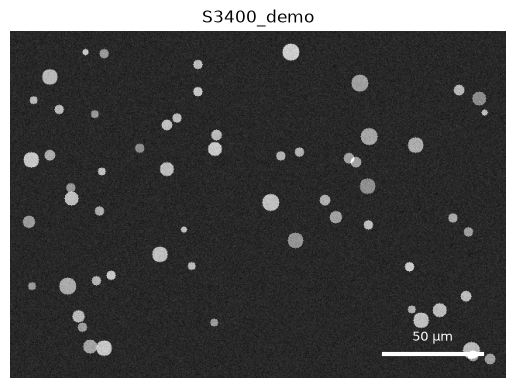

In [7]:
ax = ds.plot()          # calibrated, with a scale bar
ax.set_title(ds.name)
plt.show()

## 3. Analyze

Every function works in physical units and adds itself to the dataset's history: its parameters, the input and output content hashes, software versions, who ran it and when.

In [8]:
an.stats(ds)

{'mean': 64.26474609375,
 'std': 25.489633723594128,
 'min': 23.0,
 'max': 255.0,
 'p1': 41.0,
 'p99': 198.0,
 'noise_sigma': 8.167617958040202,
 'snr': 19.22225069862006,
 'provenance': <nuscope.provenance.Provenance at 0x1210b64b0>}

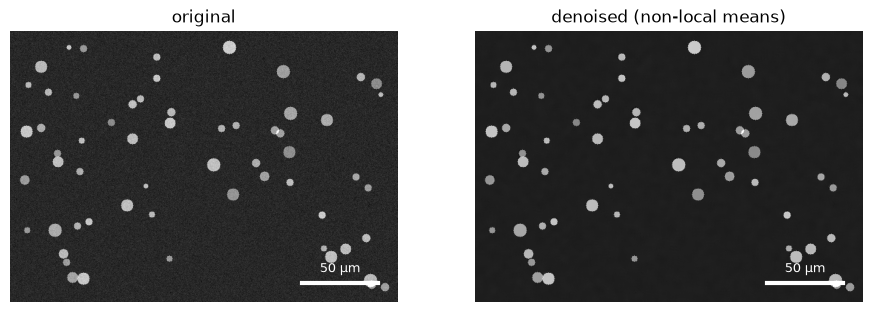

In [9]:
clean = an.denoise(ds, method="nlm")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ds.plot(ax=axs[0]); axs[0].set_title("original")
clean.plot(ax=axs[1]); axs[1].set_title("denoised (non-local means)")
plt.show()

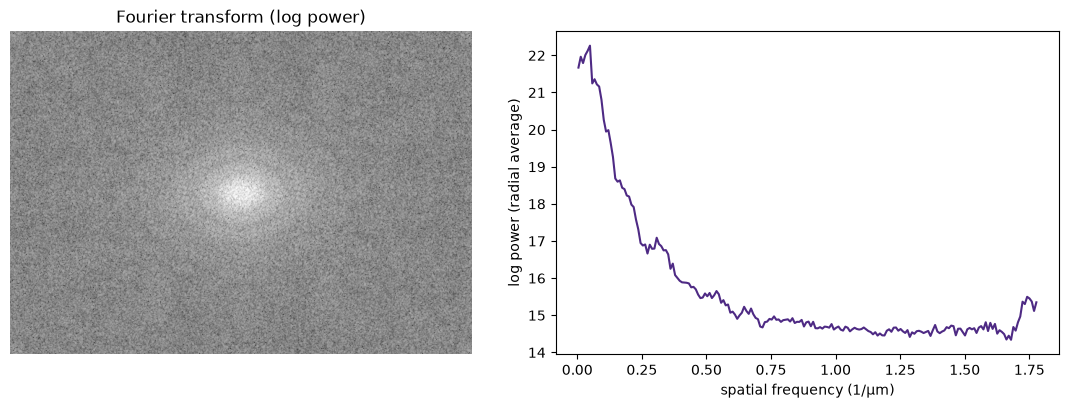

In [10]:
spectrum = an.fft(ds)                       # log power spectrum, axes in 1/nm
profile = an.radial_profile(spectrum)       # azimuthal average; columns q (1/nm) and period (nm)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
spectrum.plot(ax=axs[0], scalebar=False); axs[0].set_title("Fourier transform (log power)")
p = profile[profile.q > 0]
axs[1].plot(p.q * 1e3, p.intensity, color="#4E2A84")      # SEM scale: 1/µm reads better than 1/nm
axs[1].set_xlabel("spatial frequency (1/µm)"); axs[1].set_ylabel("log power (radial average)")
plt.tight_layout(); plt.show()

### Particles

Area, equivalent diameter, Feret, aspect ratio, circularity and orientation, in nm and nm². The table carries its own history.

In [11]:
parts = an.particles(clean, min_area_nm2=20_000)
print(f"{len(parts)} particles, area fraction {parts.attrs['area_fraction']:.1%}, "
      f"median diameter {parts.eq_diameter_nm.median() / 1000:.2f} µm")
parts[["area_nm2", "eq_diameter_nm", "aspect_ratio", "circularity"]].describe().round(1)

56 particles, area fraction 3.8%, median diameter 5.47 µm


,area_nm2,eq_diameter_nm,aspect_ratio,circularity
count,56.0,56.0,56.0,56.0
mean,30635649.4,5972.0,1.1,0.9
std,18780482.5,1844.5,0.2,0.1
min,7717978.5,3134.8,1.0,0.6
25%,17798603.5,4760.5,1.0,0.9
50%,23468955.1,5466.4,1.0,0.9
75%,49930595.7,7973.3,1.0,1.0
max,89465546.9,10672.9,2.1,1.0


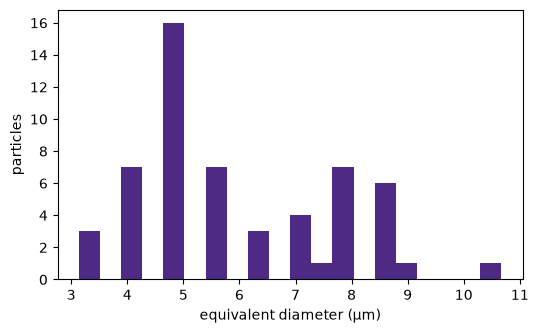

In [12]:
ax = plt.figure(figsize=(6, 3.5)).gca()
ax.hist(parts.eq_diameter_nm / 1000, bins=20, color="#4E2A84")
ax.set_xlabel("equivalent diameter (µm)"); ax.set_ylabel("particles")
plt.show()

## 4. Save: HDF5 with a seal

`.h5` (NeXus layout) is readable by h5py, HDFView and MATLAB, and NUScope also writes `.nxs`, `.zarr` and `.tif`. Every file carries the data, the calibration, both metadata blocks, the full history, and a **seal**: SHA-256 hashes of the data, calibration, metadata and history, plus the instrument DOI. If you have an identity, the seal is signed with it.

In [13]:
h5 = ns.save(clean, WORK / "S3400_demo_clean.h5")
print(h5)

/var/folders/r1/jgb817xs44qfx69d473y6rcm0000gn/T/nuscope-workflow-hjszqyj3/S3400_demo_clean.h5


In [14]:
import h5py
with h5py.File(h5) as f:
    print("root attributes:", dict(f.attrs))
    print("data:", f["entry/data/data"].shape, f["entry/data/data"].dtype)
    print("seal manifest:", json.dumps(json.loads(f["entry/nuscope/seal"][()])["manifest"], indent=1)[:900], "...")

root attributes: {'NX_class': 'NXroot', 'creator': 'NUScope', 'default': 'entry', 'nuscope_seal': '3bbb4c283900579e3b90c0ad906c0f134b9992a463cdeda2b779af9a06bbfcd1', 'nuscope_signed_by': 'Example Researcher [9d02:cb2d:cfa0:a4c0]'}
data: (448, 640) float32
seal manifest: {
 "schema": "nuscope.seal/1",
 "created": "2026-10-15T17:51:08.167+00:00",
 "data": {
  "sha256": "b2d2a9e50994c446e2f7845991e9a3419c37e4d6f58c83650ae8f2290133b7f2",
  "dtype": "<f4",
  "shape": [
   448,
   640
  ]
 },
 "axes_sha256": "292e95bf1c95c5ef2ccdafe08fe21fcf4033357bc28e899abc72fad8d008668d",
 "metadata_sha256": "44d13bf77db591da1d96f1b29999ae463f5b38d247594384c5f6f87fea5dc100",
 "provenance_sha256": "432dce80233f9b8bce62e7e671594f6b75351bd5472035ea59f1d0ab019167dd",
 "provenance_heads": [
  "721523dcc8c80ba8d2e1df41cf838e75e6d21ae452a78c5c275014c8f9667e41"
 ],
 "steps": 3,
 "instruments": [
  {
   "doi": "10.82427/nuance.epic.sem.s3400.2025.000001",
   "name": "EPIC SEM Hitachi S-3400"
  }
 ]
} ...


## 5. Verify, and what happens when a file changes

In [15]:
report = ns.verify(h5)
print(report)

SIGNED AND INTACT  seal 3bbb4c283900579e…
  sealed 2026-10-15T17:51:08.167+00:00
  ✓ data
  ✓ calibration
  ✓ metadata
  ✓ history
  ✓ history chain
  ✓ signed by Example Researcher (https://orcid.org/0000-0002-1825-0097), key 9d02:cb2d:cfa0:a4c0, author, 2026-10-15T17:51:08.167+00:00, trusted
  instrument EPIC SEM Hitachi S-3400 https://doi.org/10.82427/nuance.epic.sem.s3400.2025.000001


In [16]:
import shutil
edited = WORK / "edited.h5"
shutil.copy(h5, edited)
with h5py.File(edited, "r+") as f:          # change one pixel, quietly
    f["entry/data/data"][100, 100] += 1
print(ns.verify(edited))

CHANGED AFTER SEALING  seal 3bbb4c283900579e…
  sealed 2026-10-15T17:51:08.167+00:00
  ✗ data
  ✓ calibration
  ✓ metadata
  ✓ history
  ✓ history chain
  ✓ signed by Example Researcher (https://orcid.org/0000-0002-1825-0097), key 9d02:cb2d:cfa0:a4c0, author, 2026-10-15T17:51:08.167+00:00, trusted
  instrument EPIC SEM Hitachi S-3400 https://doi.org/10.82427/nuance.epic.sem.s3400.2025.000001
  ! data changed after sealing


`ns.load()` runs this check on every NUScope file it opens. It puts the report in `ds.integrity`, warns if anything changed, and records the result in the history. From a terminal: `nuscope verify file.h5`.

In [17]:
reopened = ns.load(h5)
reopened.integrity.status, reopened.integrity.instruments

('signed',
 [{'doi': '10.82427/nuance.epic.sem.s3400.2025.000001',
   'name': 'EPIC SEM Hitachi S-3400'}])

## 6. Trace: the full history

Every step is hash-chained, so editing any one afterwards breaks the chain.

In [18]:
print("\n".join(reopened.provenance.lineage()))
print("\nchain intact:", reopened.provenance.check_chain())

2026-10-15T17:51:06.863+00:00  io.read.hitachi(crop_databar=True)  from S3400_demo.tif
2026-10-15T17:51:07.841+00:00  analyze.denoise(method=nlm, strength=1.0)  from S3400_demo
2026-10-15T17:51:08.166+00:00  io.save.h5(path=S3400_demo_clean.h5)  from analyze.denoise(S3400_demo)
2026-10-15T17:51:08.325+00:00  io.read.nuscope(integrity=signed, seal=3bbb4c283900579e3b90c0ad906c0f134b9992a463cdeda2b779af9a06bbfcd1, signed_by=['9d02:cb2d:cfa0:a4c0'])  from S3400_demo_clean.h5

chain intact: (True, [])


In [19]:
prov = reopened.provenance.to_prov_json()          # W3C PROV-JSON
print({k: len(v) for k, v in prov.items() if isinstance(v, dict)})

{'prefix': 1, 'entity': 4, 'activity': 4, 'agent': 3, 'used': 4, 'wasGeneratedBy': 3, 'wasAssociatedWith': 9}


## 7. Cite: a DOI for the dataset

`nuscope.datacite.dataset_payload()` builds DataCite metadata for a dataset DOI. Only intact, sealed files can be cited. It links:

- the **instrument** that collected the data (`IsCollectedBy` → instrument DOI);
- the **exact file**: the seal id and the file's SHA-256;
- the **people**: creators with ORCID iDs, taken from the file's signatures (or your identity).

`register_draft()` (or `nuscope cite --draft`) creates a **draft** DOI with the facility's DataCite credentials. Publishing is permanent and never automatic, so this notebook only builds the metadata.

In [20]:
from nuscope import datacite
try:
    attrs = datacite.dataset_payload(h5, title="Ti alloy BSE (NUScope workflow demo)",
                                     description="Denoised BSE image with particle analysis.")
    print(json.dumps({k: attrs[k] for k in ("relatedIdentifiers", "alternateIdentifiers", "creators", "dates")}, indent=1))
except ValueError as e:
    print("Not citable yet:", e)

{
 "relatedIdentifiers": [
  {
   "relatedIdentifier": "10.82427/nuance.epic.sem.s3400.2025.000001",
   "relatedIdentifierType": "DOI",
   "relationType": "IsCollectedBy",
   "resourceTypeGeneral": "Instrument"
  }
 ],
 "alternateIdentifiers": [
  {
   "alternateIdentifier": "sha256:3bbb4c283900579e3b90c0ad906c0f134b9992a463cdeda2b779af9a06bbfcd1",
   "alternateIdentifierType": "NUScope seal SHA-256"
  },
  {
   "alternateIdentifier": "sha256:c80e0f7fbf0f30855a77ee13e4dfaa4ba578e4a3f610c4b5e53633066d0fd18b",
   "alternateIdentifierType": "SHA-256"
  }
 ],
 "creators": [
  {
   "name": "Researcher, Example",
   "nameType": "Personal",
   "givenName": "Example",
   "familyName": "Researcher",
   "nameIdentifiers": [
    {
     "nameIdentifier": "https://orcid.org/0000-0002-1825-0097",
     "nameIdentifierScheme": "ORCID",
     "schemeUri": "https://orcid.org"
    }
   ],
   "affiliation": [
    {
     "name": "Northwestern University",
     "affiliationIdentifier": "https://ror.org/000e0

## 8. Package for a repository (RO-Crate)

The datasets, plus an `ro-crate-metadata.json` that describes files, people, instruments, every processing step and each file's seal. Zip it and upload it to a repository that issues DOIs.

In [21]:
from nuscope.crate import write_crate
crate = write_crate([clean], WORK / "deposit", title="Ti alloy BSE (NUScope workflow demo)")
graph = json.loads(crate.read_text())["@graph"]
print(crate)
print(sorted({x["@type"] if isinstance(x["@type"], str) else x["@type"][0] for x in graph}))

/var/folders/r1/jgb817xs44qfx69d473y6rcm0000gn/T/nuscope-workflow-hjszqyj3/deposit/ro-crate-metadata.json
['CreateAction', 'CreativeWork', 'Dataset', 'File', 'IndividualProduct', 'Organization', 'Person', 'SoftwareApplication']


## 9. The same in the browser: NUScope Studio

```bash
pip install "nuscope[studio]"
nuscope studio /path/to/your/data --open
```

Studio lets you browse, view with scale bars, measure, analyze, check seals and signatures in the History tab, save, export figures and package, all on your own computer.

**Also see:** `nuscope --help` · [NUScope-TOMO](https://github.com/NUANCE-IT/NUScope-TOMO) for FIB-SEM tomography · [NUANCE-MCP](https://github.com/NUANCE-IT/NUANCE-MCP) to drive microscopes from an LLM, with every acquisition saved as a sealed, signed file.

In [22]:
print("Files from this notebook:", WORK)
for p in sorted(WORK.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(WORK)}  {p.stat().st_size:,} bytes")

Files from this notebook: /var/folders/r1/jgb817xs44qfx69d473y6rcm0000gn/T/nuscope-workflow-hjszqyj3
  S3400_demo.tif  286,976 bytes
  S3400_demo.txt  172 bytes
  S3400_demo_clean.h5  941,173 bytes
  deposit/S3400_demo.nxs  941,821 bytes
  deposit/ro-crate-metadata.json  5,345 bytes
  edited.h5  955,270 bytes
